# HCF Nested Tube — Complex Scalar FEM + PML (Research v0.1)

**목적:** 기존 HCF Designer의 코어 직경 / 튜브 수 / nested level / 두께 / 비율로 실제 **2D 스칼라 삼각형 FEM 복소 고유모드**를 구하고, 파장마다 FEM을 재실행하여 복소 `neff(λ)`와 **공진/반공진 후보**를 탐색합니다.

**필수 한계:** Full-vector Maxwell FEM이 아닙니다. 단면 벽의 Delaunay 메시가 엄밀한 경계 정합형이 아니며, PML/mesh/domain convergence가 달성되지 않았습니다. 출력하는 dB/km는 `unverified` 예비값으로만 사용하세요. 공진 위치는 **FEM 손실 스펙트럼의 국소 극값 후보**일 뿐 인증된 값이 아닙니다.

**사용 순서:** (1) 웹의 HCF Designer에서 설계 → 설계 JSON 다운로드, (2) 아래 `UPLOAD_DESIGN = True`로 바꿔 Colab 업로드, (3) 전체 실행, (4) 결과 JSON을 기존 웹의 HCF FEM 패널로 가져오기.

In [1]:
# 필요 환경: Python 3.10+, NumPy, SciPy, Matplotlib
from pathlib import Path
import sys, json, csv, os, time, importlib.util
import numpy as np
import matplotlib.pyplot as plt
if importlib.util.find_spec('scipy') is None:
    %pip -q install scipy
SOURCE = Path('hcf_complex_fem.py')
if not SOURCE.exists():
    # Colab: 공개 GitHub에서 실제 계산 소스를 가져옵니다. 자체 코드를 복사한 근사치가 아닙니다.
    import urllib.request
    url='https://raw.githubusercontent.com/kimheeseo/LSCNS/main/COMSOL/universal_silica_v01/hcf_complex_fem/hcf_complex_fem.py'
    urllib.request.urlretrieve(url,str(SOURCE))
from hcf_complex_fem import HCFDesign,design_from_dict,geometry,solve,sweep,convergence_check,C_LIGHT
print('FEM 소스 경로:',SOURCE.resolve())

FEM 소스 경로: /mnt/data/hcf_complex_fem/hcf_complex_fem.py


## 1. HCF 튜브 설계 입력

`UPLOAD_DESIGN=True`로 설정하면 기존 HCF 웹 설계기에서 내려받은 JSON을 사용할 수 있습니다. 아래 값은 전부 **예제 입력**이며 제조사 실측 파라미터가 아닙니다.

In [2]:
UPLOAD_DESIGN = False  # Colab에서 웹 설계 JSON을 업로드할 때 True
INPUT_FILE = 'HCF_design_for_scalar_complex_FEM.json'
if UPLOAD_DESIGN:
    try:
        from google.colab import files
        uploaded=files.upload()
        INPUT_FILE=next(iter(uploaded))
    except ImportError:
        print('로컬 실행: 현재 폴더에',INPUT_FILE,'를 넣어주세요.')
    design=design_from_dict(json.loads(Path(INPUT_FILE).read_text()))
else:
    design=HCFDesign()
print('코어 직경:',design.coreDiameterUm,'um · 튜브:',design.tubeCount,'×',design.nesting,'중 · 분석 기준 파장:',design.wavelengthNm,'nm')
print('Silica wall thickness (um):',design.wall1Um,design.wall2Um,design.wall3Um)

코어 직경: 32.0 um · 튜브: 6 × 2 중 · 분석 기준 파장: 1550.0 nm
Silica wall thickness (um): 0.58 0.45 0.36


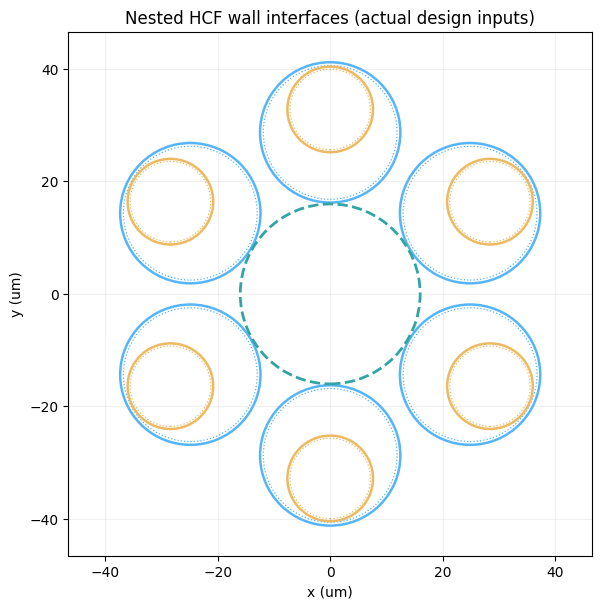

In [3]:
# 실제 단면 XY 시각화 (입력값에 따른 중첩 튜브 반영)
from matplotlib.patches import Circle
geo=geometry(design)
fig,ax=plt.subplots(figsize=(6.8,6.8))
for tube in geo['tubes']:
    col=['#56b5f9','#eeba61','#bc89f8'][tube['layer']-1]
    ax.add_patch(Circle((tube['x'],tube['y']),tube['r'],facecolor='none',edgecolor=col,linewidth=1.8))
    ax.add_patch(Circle((tube['x'],tube['y']),tube['r']-tube['wall'],facecolor='none',edgecolor=col,linewidth=.9,linestyle=':'))
ax.add_patch(Circle((0,0),geo['core_radius_um'],facecolor='none',edgecolor='#30a5a3',linewidth=2.0,linestyle='--'))
limit=geo['radius_extent_um']*1.13
ax.set(xlim=(-limit,limit),ylim=(-limit,limit),xlabel='x (um)',ylabel='y (um)',title='Nested HCF wall interfaces (actual design inputs)',aspect='equal')
ax.grid(alpha=.18)
plt.show()

## 2. 파장별 실제 Scalar FEM + PML 고유모드 계산

각 파장마다 삼각형 P1 고유값 문제를 새로 풀고, 복소 `n_eff` 및 주어진 PML의 감쇠 값을 계산합니다. **FEM 공진/반공진 후보는 손실의 이산 국소 극값**으로 표시합니다. ARROW 위상식으로 결과를 만들어내지 않습니다.

In [4]:
# 파장 스텝을 촘촘히 하고 mesh/PML 수렴을 확인해야 공진 위치에 의미가 생깁니다.
WAVELENGTHS_NM = list(np.arange(750,1801,50,dtype=float))
OUT=Path('hcf_fem_results');OUT.mkdir(exist_ok=True)
start=time.time()
result=sweep(design,WAVELENGTHS_NM,include_field_for_center=True)
result['metadata']={'solver':'2D scalar P1 complex FEM+PML','validated_for_loss':False,'source':'LSCNS/hcf_complex_fem/hcf_complex_fem.py'}
(OUT/'HCF_FEM_sweep_result.json').write_text(json.dumps(result,indent=2),encoding='utf-8')
print('파장 수:',len(result['results']),'· 실행 시간:',round(time.time()-start,2),'초')
print('검출 후보:',[(e['kind'],e['wavelength_nm']) for e in result['extrema_candidates']])

파장 수: 22 · 실행 시간: 2.93 초
검출 후보: [('resonance_loss_peak_candidate', 850.0), ('antiresonance_loss_dip_candidate', 900.0), ('antiresonance_loss_dip_candidate', 1250.0), ('resonance_loss_peak_candidate', 1300.0), ('antiresonance_loss_dip_candidate', 1400.0), ('resonance_loss_peak_candidate', 1450.0), ('antiresonance_loss_dip_candidate', 1500.0), ('resonance_loss_peak_candidate', 1550.0), ('antiresonance_loss_dip_candidate', 1600.0)]


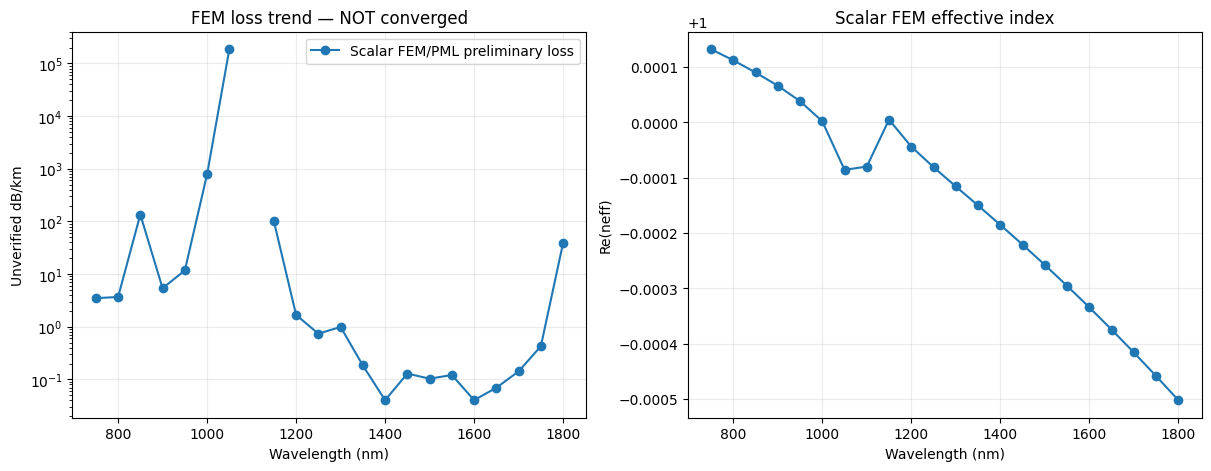

750 nm · Re(neff)=1.000132323, Im(neff)=4.796e-11, J0 overlap=0.981, mode OK=True
800 nm · Re(neff)=1.000112337, Im(neff)=5.376e-11, J0 overlap=0.982, mode OK=True
850 nm · Re(neff)=1.000090276, Im(neff)=2.103e-09, J0 overlap=0.978, mode OK=True
900 nm · Re(neff)=1.000066358, Im(neff)=8.876e-11, J0 overlap=0.985, mode OK=True
950 nm · Re(neff)=1.000038490, Im(neff)=2.041e-10, J0 overlap=0.986, mode OK=True
1000 nm · Re(neff)=1.000002098, Im(neff)=1.436e-08, J0 overlap=0.985, mode OK=True
1050 nm · Re(neff)=0.999914366, Im(neff)=3.582e-06, J0 overlap=0.820, mode OK=True
1100 nm · Re(neff)=0.999920174, Im(neff)=5.705e-05, J0 overlap=0.054, mode OK=False
1150 nm · Re(neff)=1.000004963, Im(neff)=2.134e-09, J0 overlap=0.922, mode OK=True
1200 nm · Re(neff)=0.999956342, Im(neff)=3.695e-11, J0 overlap=0.953, mode OK=True
1250 nm · Re(neff)=0.999919212, Im(neff)=1.690e-11, J0 overlap=0.962, mode OK=True
1300 nm · Re(neff)=0.999884364, Im(neff)=2.361e-11, J0 overlap=0.967, mode OK=True
1350 nm 

In [5]:
# FEM-derived spectrum plot: invalid mode overlap is drawn as untrusted, not a physical peak.
rows=result['results'];wl=np.array([r['input']['wavelengthNm'] for r in rows])
loss=np.array([r['confinement_loss_dB_km_unverified'] if r['mode_identification_pass'] and r['confinement_loss_dB_km_unverified'] is not None else np.nan for r in rows])
real=np.array([r['neff_real'] for r in rows]);imag=np.array([r['neff_imag'] for r in rows])
fig,axs=plt.subplots(1,2,figsize=(12,4.6),layout='constrained')
axs[0].semilogy(wl,loss,'o-',label='Scalar FEM/PML preliminary loss')
axs[0].set(xlabel='Wavelength (nm)',ylabel='Unverified dB/km',title='FEM loss trend — NOT converged')
axs[0].grid(alpha=.25);axs[0].legend()
axs[1].plot(wl,real,'o-');axs[1].set(xlabel='Wavelength (nm)',ylabel='Re(neff)',title='Scalar FEM effective index');axs[1].grid(alpha=.25)
fig.savefig(OUT/'HCF_FEM_spectrum.png',dpi=150)
plt.show()
for r in rows:
    print(f"{r['input']['wavelengthNm']:.0f} nm · Re(neff)={r['neff_real']:.9f}, Im(neff)={r['neff_imag']:.3e}, J0 overlap={r['ideal_J0_overlap']:.3f}, mode OK={r['mode_identification_pass']}")

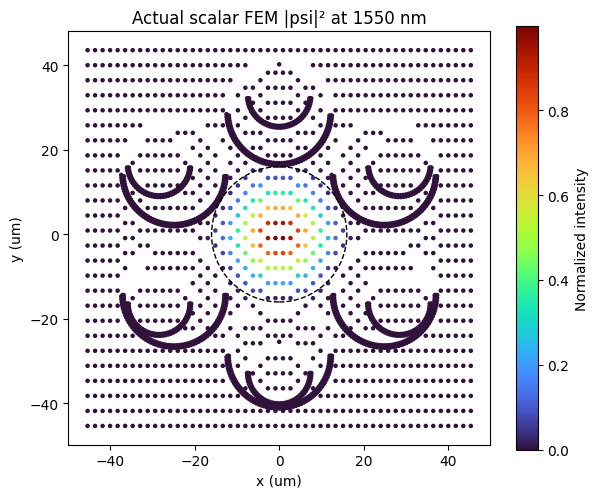

In [6]:
# 계산에서 추출한 실제 스칼라 FEM 모드 분포 (가우시안 예시를 만든 것이 아님)
field=next((r for r in rows if r.get('mode_points')),None)
if field:
    pts=field['mode_points']
    fig,ax=plt.subplots(figsize=(6.8,5.5))
    m=ax.scatter([p['x_um'] for p in pts],[p['y_um'] for p in pts],c=[p['intensity'] for p in pts],s=5,cmap='turbo')
    ax.add_patch(Circle((0,0),field['geometry']['core_radius_um'],fill=False,edgecolor='black',linestyle='--'))
    ax.set(title=f"Actual scalar FEM |psi|² at {field['input']['wavelengthNm']:.0f} nm",xlabel='x (um)',ylabel='y (um)',aspect='equal')
    fig.colorbar(m,ax=ax,label='Normalized intensity')
    fig.savefig(OUT/'HCF_FEM_mode_field.png',dpi=150)
    plt.show()

## 3. 메시·PML 변경에 대한 정량 수렴 검사

**검증이 통과하지 않으면 손실값을 실측값/제품 사양과 비교하지 마세요.** 기본 조건은 수렴되지 않을 가능성이 높습니다.

In [7]:
conv=convergence_check(design)
(OUT/'HCF_FEM_convergence.json').write_text(json.dumps(conv,indent=2),encoding='utf-8')
print('mesh 상대 차이(%)',conv['relative_mesh_change_pct'])
print('PML 상대 차이(%)',conv['relative_pml_change_pct'])
print('2-point preliminary criterion passed?',conv['preliminary_loss_convergence_pass'])
print('Note:',conv['note'])

mesh 상대 차이(%) 499.191210292381
PML 상대 차이(%) 69.4281256926018
2-point preliminary criterion passed? False
Note: Even 5% 2-point convergence is insufficient for publication-grade HCF confinement loss; domain and mode checks also required.


In [8]:
# CSV + ZIP + Colab 다운로드
with (OUT/'HCF_FEM_spectrum.csv').open('w',newline='',encoding='utf-8') as f:
    w=csv.writer(f);w.writerow(['lambda_nm','neff_real','neff_imag','loss_dB_km_UNVERIFIED','core_power_frac','J0_overlap','mode_identification_pass'])
    for r in rows:w.writerow([r['input']['wavelengthNm'],r['neff_real'],r['neff_imag'],r['confinement_loss_dB_km_unverified'],r['air_core_power_fraction'],r['ideal_J0_overlap'],r['mode_identification_pass']])
import shutil
archive=shutil.make_archive('HCF_complex_FEM_Results','zip',root_dir=str(OUT))
print('저장 완료:',archive)
try:
    from google.colab import files
    files.download(str(OUT/'HCF_FEM_sweep_result.json'))
    files.download(archive)
except ImportError:
    pass

저장 완료: /mnt/data/hcf_complex_fem/HCF_complex_FEM_Results.zip


## 4. 논문·COMSOL 정량 검증 전 추가로 필요한 것

- **Full-vector edge-element FEM** (현재 스칼라 모드는 HE/EH/TE/TM 모드를 정확하게 분리하지 못함)
- **경계 정합 메시**, 튜브 벽 최소 3~5 요소와 모서리/공극 정밀 세분화
- **PML 세기·두께·도메인 크기** 독립 수렴, 메시 수렴, 동일 모드 추적
- **파장 간격 세분화 및 공진 모드 결합** 확인
- COMSOL 공개 예제 및 검증된 NANF 논문 데이터와 **복소 neff·손실 스펙트럼** 대조

광 강도의 시각화가 정교해져도 위 검증을 대체할 수 없습니다.